# İş Akışı ve Hiperparametre Optimizasyonu

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np

🏠 Ev fiyatları veri setini içe aktarın. Basitlik adına sadece sayısal özellikleri tutacağız

🎯 Hedefiniz en iyi KNN Regressor'ı yerleştirmek olacak. Özellikle, ev fiyatlarınız için en iyi tahminleri elde etmek üzere kaç tane "komşu" (<font color=blue>K</font>NN'deki <font color=blue>K</font>) göz önünde bulundurmalısınız?

In [2]:
# Load raw data
data = pd.read_csv('https://d32aokrjazspmn.cloudfront.net/materials/houses_train_raw.csv', index_col="Id")

# Only keep numerical columns and raws without NaN
data = data.select_dtypes(include=np.number).dropna()

data

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,61,0,0,0,0,0,2,2008,208500
2,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,298,0,0,0,0,0,0,5,2007,181500
3,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,42,0,0,0,0,0,9,2008,223500
4,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,35,272,0,0,0,0,2,2006,140000
5,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,192,84,0,0,0,0,0,12,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,60,62.0,7917,6,5,1999,2000,0.0,0,0,...,0,40,0,0,0,0,0,8,2007,175000
1457,20,85.0,13175,6,6,1978,1988,119.0,790,163,...,349,0,0,0,0,0,0,2,2010,210000
1458,70,66.0,9042,7,9,1941,2006,0.0,275,0,...,0,60,0,0,0,0,2500,5,2010,266500


In [3]:
X = data.drop(columns=['SalePrice'])
y = data['SalePrice']

## 1. Eğitim/Test Ayrımı

❓ **Soru (Holdout)**❓

👇 `X_train`, `X_test`, `y_train` ve `y_test` oluşturmak için veri setini böl. Şunları kullan:
- `test_size=0.3`
- Sonuçlarınızı arkadaşınızla karşılaştırmak için `random_state=0`

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=0
)

print("Eğitim seti:", X_train.shape)
print("Test seti:", X_test.shape)

Eğitim seti: (784, 36)
Test seti: (337, 36)


## 2. Ölçeklendirme

⚖️ Ölçeklendirme KNN algoritması için her zaman kritik derecede önemlidir..

❓ **Soru (Ölçeklendirme)** ❓ 

* Eğitim setinizi ve test setinizi ölçeklendirin.
* Burada, basitçe `StandardScaler` uygulayalım ve özellik başına bir ölçekleyici seçerek zaman kaybetmeyelim. Gerçekten de, bu egzersizin amaçları şunlardır:
    * KNN'i gözden geçirmek
    * GridSearchCV'yi anlamak
    * RandomizedSearchCV'yi anlamak

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Eğitim verisi ölçeklendirildi:", X_train_scaled.shape)
print("Test verisi ölçeklendirildi:", X_test_scaled.shape)

Eğitim verisi ölçeklendirildi: (784, 36)
Test verisi ölçeklendirildi: (337, 36)


## 3. Temel KNN modeli

❓ **Soru (KNN için bir temel)** ❓

Sadece _en yakın komşuyu_ dikkate alan basit bir KNN regressor'ı çapraz doğrulayın (*cv = 5*) ve 5 kat üzerindeki ortalama skoru hesaplayın.

In [6]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score
import numpy as np

knn = KNeighborsRegressor(n_neighbors=1)

cv_scores = cross_val_score(
    knn,
    X_train_scaled,
    y_train,
    cv=5,
    scoring="r2"
)

mean_score = cv_scores.mean()

print("5 katlı R2 skorları:", cv_scores)
print("Ortalama R2 skoru:", round(mean_score, 4))

5 katlı R2 skorları: [0.54270115 0.68418625 0.25016271 0.77858198 0.54513935]
Ortalama R2 skoru: 0.5602


## 4. GridSearch

### 4.1. İlk GridSearch

❓ **Soru (GridSearch v1)**❓

En iyi KNN hiperparametresini `n_neighbors` bulmak için SKLearn `GridSearchCV` kullanalım.
- `n_neighbors` = [1,5,10,20,50] ile kaba taneli bir yaklaşım başlat
- Her parametreyi 5-kat çapraz doğrula
- `n_jobs` kullanarak performans sürenizi maksimize ettiğinizden emin olun

In [7]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor

# Model
knn = KNeighborsRegressor()

# Hiperparametreler
param_grid = {
    "n_neighbors": [1, 5, 10, 20, 50]
}

# GridSearch
grid_search = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Modeli eğit
grid_search.fit(X_train_scaled, y_train)

print("GridSearch tamamlandı!")

GridSearch tamamlandı!


❓ **Soru (en iyi parametreler)** ❓

GridSearch'e göre, optimal K değeri nedir?

In [8]:
print("En iyi K:", grid_search.best_params_["n_neighbors"])

En iyi K: 10


❓ **Soru (puanlama)** ❓ Optimal K değerinin ürettiği en iyi skor nedir?

In [9]:
print("En iyi R2 skoru:", grid_search.best_score_)

En iyi R2 skoru: 0.7596697382171873


### 4.2. İkinci GridSearch

❓ **Soru (GridSearch V2)** ❓

Şimdi, en iyi $K$'nın nerede olduğu hakkında bir fikrimiz var, ancak denemediğimiz bazı değerler daha iyi bir performansla sonuçlanabilir.

* Önceki en iyi değerinizin çevresindeki $K$ için bazı değerleri deneyerek GridSearch'ü yeniden çalıştırın
* Bu rafine edilmiş GridSearch için `best_score` ve `best_k` nelerdir?

In [10]:
# İlk GridSearch sonucundaki en iyi K
initial_best_k = grid_search.best_params_["n_neighbors"]

# En iyi K'nın çevresindeki değerler
refined_k = list(range(
    max(1, initial_best_k - 5),
    initial_best_k + 6
))

# İkinci GridSearch
grid_search_v2 = GridSearchCV(
    estimator=KNeighborsRegressor(),
    param_grid={"n_neighbors": refined_k},
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search_v2.fit(X_train_scaled, y_train)

best_k = int(grid_search_v2.best_params_["n_neighbors"])
best_score = float(grid_search_v2.best_score_)

print("En iyi K:", best_k)
print("En iyi R2 skoru:", best_score)

En iyi K: 15
En iyi R2 skoru: 0.7657859104933367


***🧪 Kodunuzu test edin***

In [12]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'knn',
    best_k=best_k,
    best_score=best_score
)

result.write()
print(result.check())


============================= test session starts =============================
platform win32 -- Python 3.13.16, pytest-9.2.0, pluggy-1.7.0 -- c:\Users\User\AppData\Local\Programs\Python\Python313\python.exe
cachedir: .pytest_cache
rootdir: c:\Users\User\Desktop\D16D5-S-data-workflow\tests
plugins: platformdirs-4.14.0
collecting ... collected 2 items

test_knn.py::TestKnn::test_best_k PASSED                                 [ 50%]
test_knn.py::TestKnn::test_best_score PASSED                             [100%]

============================== 2 passed in 0.05s ==============================


💯 You can commit your code:

git add tests/knn.pickle

git commit -m 'Completed knn step'

git push origin master



### 4.3. Görsel kontrol (manuel GridSearch)

☝️ Bu problem aslında manuel olarak GridSearch yapmak için yeterince basittir.

❓ **Soru(Manuel GridSearch)** ❓

- $K$'nın $1$'den $50$'ye kadar tüm değerleri üzerinde manuel olarak döngü yapın ve her modelin çapraz doğrulanmış skorlarının ortalamasını bir listede saklayın.
- `Dirsek Yöntemi` kullanarak en iyi $K$'yı görsel olarak bulmak için skorları $K$'nın bir fonksiyonu olarak çizin

En iyi K: 16
En iyi R2: 0.7666311417513013


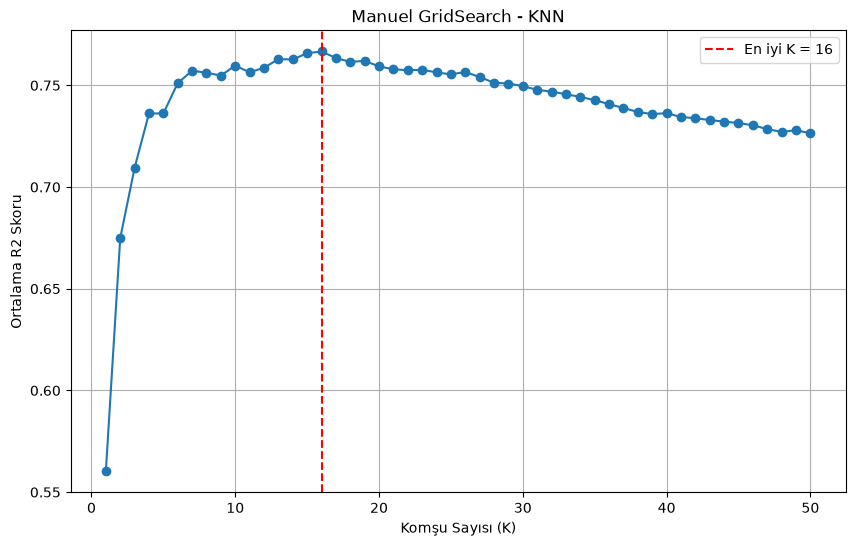

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score

k_values = range(1, 51)
mean_scores = []

for k in k_values:
    model = KNeighborsRegressor(n_neighbors=k)

    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5,
        scoring="r2",
        n_jobs=-1
    )

    mean_scores.append(scores.mean())

best_manual_k = np.argmax(mean_scores) + 1

print("En iyi K:", best_manual_k)
print("En iyi R2:", max(mean_scores))

plt.figure(figsize=(10, 6))
plt.plot(k_values, mean_scores, marker="o")
plt.axvline(best_manual_k, color="red", linestyle="--",
            label=f"En iyi K = {best_manual_k}")

plt.xlabel("Komşu Sayısı (K)")
plt.ylabel("Ortalama R2 Skoru")
plt.title("Manuel GridSearch - KNN")
plt.legend()
plt.grid(True)
plt.show()

❓GridSearchCV'yi böyle bir manuel döngüden daha iyi bir seçenek yapan şeyi tahmin edebilir misiniz?

<details>
    <summary>Cevap</summary>

- Sklearn'ın `n_jobs=-1` seçeneği aramayı paralelleştirmenize izin verir, tüm CPU çekirdeklerinizi kullanır
- Birlikte optimize edilecek birden fazla hiperparametreniz olsaydı ne olurdu?
</details>

## 5. Birden çok parametre ile GridSearch

👩🏻‍🏫 KNNRegressor, `p` hiperparametresi aracılığıyla çeşitli _mesafe metrikleri_ destekler

📚 [sklearn.neighbors.KNeighborsRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)

❓ **Soru (birden çok parametreyi ayarlama)** ❓

* En iyi $K$ ve $p$'yi aynı anda aramak için GridSearchCV kullanın.
    * $K = [1, 5, 10, 20, 50]$ ve $p = [1, 2, 3]$ için tüm kombinasyonları deneyin.

In [14]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor

param_grid_multi = {
    "n_neighbors": [1, 5, 10, 20, 50],
    "p": [1, 2, 3]
}

grid_multi = GridSearchCV(
    estimator=KNeighborsRegressor(),
    param_grid=param_grid_multi,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_multi.fit(X_train_scaled, y_train)

print("GridSearch tamamlandı!")

GridSearch tamamlandı!


❓ **Soru (alt model sayısı)**❓

Toplamda kaç alt model eğittiniz?

<details>
    <summary>İpucu</summary>

15'ten çok daha fazla. İki kez düşün :)
    <details>
    <summary>Cevap</summary>

CV=5 nedeniyle 75 model
</details>

In [15]:
total_models = (
    len(param_grid_multi["n_neighbors"])
    * len(param_grid_multi["p"])
    * grid_multi.cv
)

print("Eğitilen alt model sayısı:", total_models)

Eğitilen alt model sayısı: 75


❓ **Soru (modeli birden çok parametre ile ayarladıktan sonra en iyi parametreler ve en iyi skor)**❓

*En iyi parametreler* ve *en iyi skor* nedir?

In [17]:
best_params_multi = grid_multi.best_params_
best_score_multi = grid_multi.best_score_

print("En iyi parametreler:", best_params_multi)
print("En iyi R2 skoru:", round(best_score_multi, 4))


En iyi parametreler: {'n_neighbors': 10, 'p': 1}
En iyi R2 skoru: 0.7969


## 6. Rastgele Arama

Şimdi bir RandomizedSearch'ün aynı sayıda model yerleştirilerek daha iyi bir kombinasyon bulup bulamayacağını görelim.

❓ **Soru (RandomizedSearchCV)** ❓

`RandomizedSearchCV` kullanarak
- $K$'yı uniform `scipy.stats.randint(1,50)` ([döküman](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.randint.html)) dağılımından rastgele örnekle
- $p$'yi $[1,2,3]$ listesinden örnekle
- Önceki GridSearchCV'nizdeki ile tam olarak aynı sayıda model yerleştirmek için doğru `n_iter` ve `cv` sayılarını kullanın.

In [18]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neighbors import KNeighborsRegressor
from scipy.stats import randint

# Hiperparametre dağılımları
param_distributions = {
    "n_neighbors": randint(1, 50),
    "p": [1, 2, 3]
}

# RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=KNeighborsRegressor(),
    param_distributions=param_distributions,
    n_iter=15,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42
)

# Modeli eğit
random_search.fit(X_train_scaled, y_train)

# Sonuçları göster
print("RandomizedSearch tamamlandı!")
print("En iyi parametreler:", random_search.best_params_)
print("En iyi R2 skoru:", round(random_search.best_score_, 4))

RandomizedSearch tamamlandı!
En iyi parametreler: {'n_neighbors': 8, 'p': 1}
En iyi R2 skoru: 0.7942


## 7. Genelleme

❓ **Soru (modelinizi bir kez daha ince ayarlama)**❓

- İsterseniz RandomsearchCV'nizi rafine edin
- En iyi modelinizi seçin

In [19]:
# GridSearch ve RandomizedSearch sonuçlarını karşılaştır
print("GridSearch R2:", grid_multi.best_score_)
print("RandomizedSearch R2:", random_search.best_score_)

# En yüksek CV skoruna sahip modeli seç
if grid_multi.best_score_ >= random_search.best_score_:
    best_search = grid_multi
else:
    best_search = random_search

best_model = best_search.best_estimator_

print("\nSeçilen model:", best_model)
print("En iyi parametreler:", best_search.best_params_)
print("En iyi CV R2:", round(best_search.best_score_, 4))

GridSearch R2: 0.7969255879201194
RandomizedSearch R2: 0.7942356840941323

Seçilen model: KNeighborsRegressor(n_neighbors=10, p=1)
En iyi parametreler: {'n_neighbors': 10, 'p': 1}
En iyi CV R2: 0.7969


Şimdi `cv_results`'ınızı bir `DataFrame` olarak görüntülemeye çalışın, bu CV'nin içinde neler olup bittiğini görselleştirmenize yardımcı olacak! 😉

In [20]:
import pandas as pd

cv_results_df = pd.DataFrame(best_search.cv_results_)

display(
    cv_results_df[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ].sort_values("rank_test_score").head(10)
)

,params,mean_test_score,std_test_score,rank_test_score
6,"{'n_neighbors': 10, 'p': 1}",0.796926,0.045769,1
3,"{'n_neighbors': 5, 'p': 1}",0.792764,0.059309,2
9,"{'n_neighbors': 20, 'p': 1}",0.779081,0.035181,3
0,"{'n_neighbors': 1, 'p': 1}",0.768976,0.077233,4
7,"{'n_neighbors': 10, 'p': 2}",0.759670,0.048466,5
10,"{'n_neighbors': 20, 'p': 2}",0.759292,0.043851,6
12,"{'n_neighbors': 50, 'p': 1}",0.743216,0.033119,7
4,"{'n_neighbors': 5, 'p': 2}",0.736176,0.079069,8
11,"{'n_neighbors': 20, 'p': 3}",0.734643,0.040267,9
8,"{'n_neighbors': 10, 'p': 3}",0.728985,0.049407,10


❓ **Soru ("En iyi" modelin değerlendirmesi)** ❓

* "En iyi parametrelerle" modelimizin **görülmemiş** test seti `X_test` üzerindeki performansını keşfetme zamanı geldi.
    * Test seti için r2 skorunu hesaplayın ve `r2_test` olarak kaydedin.

In [21]:
# Daha önce görülmemiş test verisi üzerinde değerlendirme
r2_test = best_model.score(X_test_scaled, y_test)

print("En iyi CV R2:", round(best_search.best_score_, 4))
print("Test R2:", round(r2_test, 4))
print("Performans farkı:", round(best_search.best_score_ - r2_test, 4))

En iyi CV R2: 0.7969
Test R2: 0.7731
Performans farkı: 0.0238


❓ **Soru (Bir adım geri çekilme)** ❓

Optimize edilmiş modelin iyi genelleme yaptığını düşünür müsünüz?

<details><summary>Cevap</summary>

Test skoru eğitim seti ile biraz azalabilir. Muhtemelen %5'ten fazla değil. Bunun nedeni şunlar olabilir:
- Temsili olmayan bir eğitim/test bölünmesi
- Model ayarlama aşamasında aşırı öğrenmeye yol açan çok küçük bir çapraz doğrulama sayısı. Ne kadar çok çapraz doğrulama yaparsanız, bulgularınız o kadar güçlü genelleşir - ancak veri setiniz çok küçükse cv'yi çok fazla artıramazsınız çünkü her katmanda temsili olmak için yeterli gözlemi tutamazsınız.
- Veri setimiz çok küçük ve hiperparametre optimizasyonumuz bu nedenle eğitim/test bölünmemize son derece bağımlı (ve aşırı uyum gösteriyor). Veri setinizin denediğiniz toplam hiperparametre kombinasyonu sayısından çok daha büyük olduğundan her zaman emin olun!
    
</details>

***🧪 Kodunuzu test edin***

In [22]:
from nbresult import ChallengeResult
result = ChallengeResult('r2', 
                         r2_test=r2_test)
result.write()
print(result.check())


============================= test session starts =============================
platform win32 -- Python 3.13.16, pytest-9.2.0, pluggy-1.7.0 -- c:\Users\User\AppData\Local\Programs\Python\Python313\python.exe
cachedir: .pytest_cache
rootdir: c:\Users\User\Desktop\D16D5-S-data-workflow\tests
plugins: platformdirs-4.14.0
collecting ... collected 1 item

test_r2.py::TestR2::test_r2 PASSED                                       [100%]

============================== 1 passed in 0.06s ==============================


💯 You can commit your code:

git add tests/r2.pickle

git commit -m 'Completed r2 step'

git push origin master



🏁 Tebrikler! Artık GridSearchCV veya RandomizedSearchCV kullanarak bir modeli nasıl ince ayarlayacağınızı biliyorsunuz

💾 Notebook'unuzu `git add/commit/push` yapmayı unutmayın...

🚀 ... ve bir sonraki meydan okumaya geçin!